# RoyalRoad-1.61M：EDA

資料集：`OmniAICreator/RoyalRoad-1.61M`（Hugging Face）。每一列是**一個章節**，小說層級欄位會在同一本書的每一列重複。
這份 notebook 回答：資料單位是什麼、缺值在哪、熱度與評分長什麼樣、能不能支撐「看前幾章預測熱門」這個 Project 1 題目。

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import pyarrow.parquet as pq, pyarrow.compute as pc
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
RAW = Path("../data/raw/data"); INTERIM = Path("../data/interim"); FIG = Path("../reports/eda/figs")
INTERIM.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"font.sans-serif": ["PingFang TC", "Heiti TC", "Arial Unicode MS", "DejaVu Sans"], "axes.unicode_minus": False, "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
S = {}   # 給 artifact 報告用的數字
def save(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
files = sorted(RAW.glob("*.parquet")); print(len(files), "shards")

47 shards


## 1. 載入（只讀 metadata 與文字長度，不把全文放進記憶體）

In [2]:
CH_COLS = ["fiction_id","chapter_id","release_datetime","chapter_title","total_views","followers","overall_score","favorites","ratings","pages"]
FI_COLS = ["fiction_id","title","author","status","is_original","tags","warnings","description","cover_url",
           "overall_score","style_score","story_score","grammar_score","character_score",
           "total_views","average_views","followers","favorites","ratings","pages"]
ch_path = INTERIM / f"chapters_{len(files)}.parquet"; fi_path = INTERIM / f"fictions_{len(files)}.parquet"

if not (ch_path.exists() and fi_path.exists()):
    chs, fis = [], []
    for f in files:
        pf = pq.ParquetFile(f)
        for i in range(pf.num_row_groups):
            t = pf.read_row_group(i, columns=list(dict.fromkeys(CH_COLS + FI_COLS)) + ["text"])
            txt = t.column("text")
            n_chars = pc.utf8_length(txt).to_numpy()
            n_spaces = pc.count_substring(txt, " ").to_numpy()
            df = t.drop_columns(["text"]).to_pandas()
            chs.append(df[CH_COLS].assign(n_chars=n_chars, n_spaces=n_spaces))
            fis.append(df[FI_COLS].drop_duplicates("fiction_id"))
    ch = pd.concat(chs, ignore_index=True)
    fi = pd.concat(fis, ignore_index=True).drop_duplicates("fiction_id")
    ch.to_parquet(ch_path); fi.to_parquet(fi_path)
ch = pd.read_parquet(ch_path); fi = pd.read_parquet(fi_path)
ch["release_datetime"] = pd.to_datetime(ch["release_datetime"], utc=True, errors="coerce")
ch["words"] = ch["n_spaces"] + 1          # 粗估字數（以空白計）
print(ch.shape, fi.shape)

(1613875, 13) (86959, 20)


## 2. 資料單位與規模

In [3]:
S["n_rows"] = len(ch); S["n_fictions"] = fi.fiction_id.nunique(); S["n_authors"] = fi.author.nunique()
S["date_min"] = str(ch.release_datetime.min().date()); S["date_max"] = str(ch.release_datetime.max().date())
S["n_chapter_id_dup"] = int(ch.chapter_id.duplicated().sum()); S["n_chapter_id_null"] = int(ch.chapter_id.isna().sum())
print({k: S[k] for k in ["n_rows","n_fictions","n_authors","date_min","date_max","n_chapter_id_dup","n_chapter_id_null"]})
print("總字數（粗估，十億）:", round(ch.words.sum()/1e9, 2))

{'n_rows': 1613875, 'n_fictions': 86959, 'n_authors': 56458, 'date_min': '2013-03-30', 'date_max': '2025-06-16', 'n_chapter_id_dup': 0, 'n_chapter_id_null': 1}
總字數（粗估，十億）: 3.51


In [4]:
# 小說層級欄位在同一本書內是否固定？（決定能不能直接當作 fiction-level 特徵）
g = ch.groupby("fiction_id")
const = pd.Series({c: (g[c].nunique(dropna=False) == 1).mean() for c in ["total_views","followers","overall_score","favorites","ratings","pages"]})
S["const_share"] = const.round(4).to_dict()
const.to_frame("同一本書內數值固定的比例")

,同一本書內數值固定的比例
total_views,1.000000
followers,1.000000
overall_score,1.000000
favorites,0.999966
ratings,0.999966
pages,1.000000


## 3. 缺值

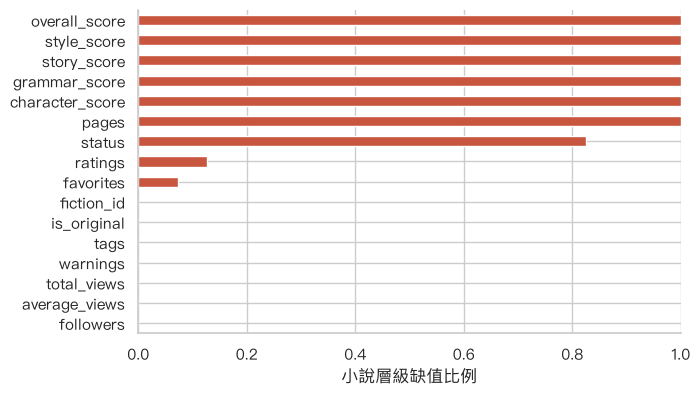

,缺值比例
overall_score,1.000
style_score,1.000
story_score,1.000
grammar_score,1.000
character_score,1.000
pages,1.000
status,0.825
ratings,0.127
favorites,0.074
fiction_id,0.000


In [5]:
na = pd.DataFrame({"chapter_level_na": ch[CH_COLS].isna().mean(), }).T
fi_na = fi.drop(columns=["title","author","description","cover_url"]).isna().mean().sort_values(ascending=False)
S["fi_na"] = fi_na.round(4).to_dict()
fig, ax = plt.subplots(figsize=(7, 4.2))
fi_na.plot.barh(ax=ax, color="#c8553d"); ax.invert_yaxis(); ax.set_xlabel("小說層級缺值比例"); ax.set_xlim(0, 1)
save("na_by_column")
fi_na.to_frame("缺值比例").round(3)

## 4. 每本小說有幾章

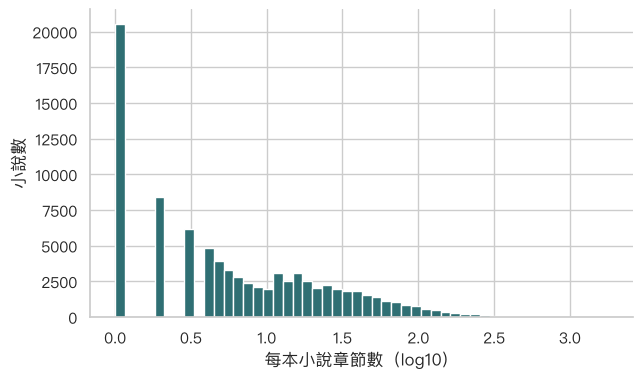

{'count': 86959.0, 'mean': 18.6, 'std': 45.1, 'min': 1.0, '10%': 1.0, '25%': 2.0, '50%': 5.0, '75%': 18.0, '90%': 45.0, '99%': 192.0, 'max': 1793.0} 
只有 1 章: 0.236  至少 3 章: 0.667


In [6]:
fi_agg = ch.sort_values("release_datetime").groupby("fiction_id").agg(
    n_chapters=("chapter_id","size"), first_release=("release_datetime","min"), last_release=("release_datetime","max"),
    med_words=("words","median"))
fi = fi.set_index("fiction_id").join(fi_agg).reset_index()
S["chapters_per_fiction"] = fi.n_chapters.describe(percentiles=[.1,.25,.5,.75,.9,.99]).round(1).to_dict()
S["share_1ch"] = float((fi.n_chapters == 1).mean()); S["share_ge3"] = float((fi.n_chapters >= 3).mean())
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(np.log10(fi.n_chapters), bins=50, color="#2f6f73"); ax.set_xlabel("每本小說章節數（log10）"); ax.set_ylabel("小說數")
save("chapters_per_fiction")
print(S["chapters_per_fiction"], "\n只有 1 章:", round(S["share_1ch"],3), " 至少 3 章:", round(S["share_ge3"],3))

## 5. 時間

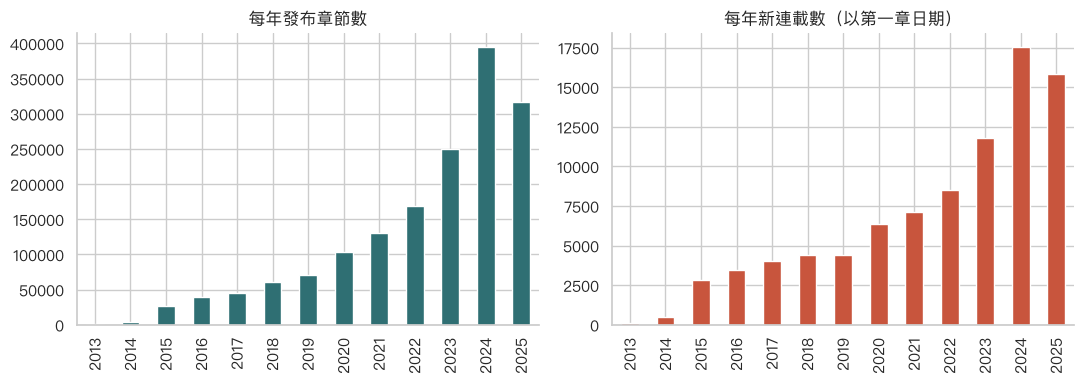

,chapters,new_fictions
2013,1053,111
2014,3879,508
2015,26844,2808
2016,39057,3476
2017,45791,4052
2018,60682,4381
2019,71327,4429
2020,103970,6373
2021,130144,7124
2022,168975,8526


In [7]:
fi["first_year"] = fi.first_release.dt.year
by_year = pd.DataFrame({"chapters": ch.groupby(ch.release_datetime.dt.year).size(), "new_fictions": fi.groupby("first_year").size()}).fillna(0)
S["by_year"] = by_year.astype(int).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
by_year.chapters.plot.bar(ax=ax[0], color="#2f6f73"); ax[0].set_title("每年發布章節數"); ax[0].set_xlabel("")
by_year.new_fictions.plot.bar(ax=ax[1], color="#c8553d"); ax[1].set_title("每年新連載數（以第一章日期）"); ax[1].set_xlabel("")
plt.tight_layout(); save("by_year")
by_year.astype(int)

## 6. 狀態與原創

In [8]:
S["status"] = fi.status.value_counts(normalize=True, dropna=False).round(4).rename(index=lambda k: "NULL" if pd.isna(k) else k).to_dict()
S["is_original"] = fi.is_original.value_counts(normalize=True).round(4).to_dict()
print(S["status"]); print(S["is_original"])
fi.groupby("status", dropna=False).agg(n=("fiction_id","size"), med_followers=("followers","median"), med_chapters=("n_chapters","median")).round(1)

{'NULL': 0.8251, 'ONGOING': 0.1118, 'COMPLETED': 0.0631}
{1: 0.9148, 0: 0.0852}


,n,med_followers,med_chapters
status,,,
COMPLETED,5486,5.0,18.0
ONGOING,9725,3.0,14.0
NaN,71748,2.0,4.0


## 7. 熱度：views 與 followers

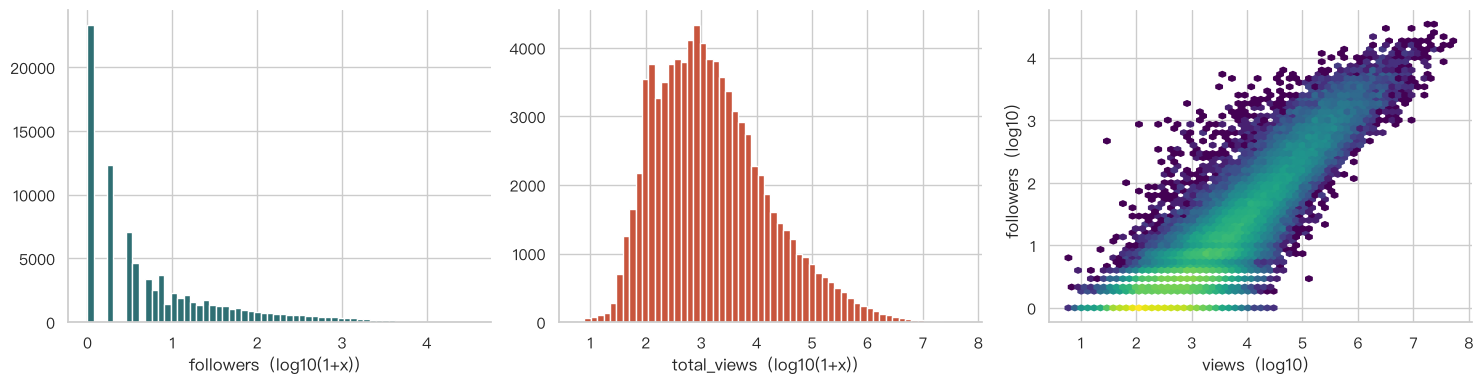

{0.5: 3, 0.75: 16, 0.9: 116, 0.95: 406, 0.99: 2386, 0.999: 9388} 
零 followers 比例: 0.268  Spearman(views,followers)= 0.837


In [9]:
S["followers_q"] = fi.followers.quantile([.5,.75,.9,.95,.99,.999]).to_dict()
S["views_q"] = fi.total_views.quantile([.5,.75,.9,.95,.99,.999]).to_dict()
S["share_zero_followers"] = float((fi.followers == 0).mean())
S["rho_views_followers"] = float(spearmanr(fi.total_views, fi.followers)[0])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(np.log10(1 + fi.followers), bins=60, color="#2f6f73"); ax[0].set_xlabel("followers（log10(1+x)）")
ax[1].hist(np.log10(1 + fi.total_views), bins=60, color="#c8553d"); ax[1].set_xlabel("total_views（log10(1+x)）")
hb = ax[2].hexbin(np.log10(1 + fi.total_views), np.log10(1 + fi.followers), gridsize=60, bins="log", cmap="viridis", mincnt=1)
ax[2].set_xlabel("views（log10）"); ax[2].set_ylabel("followers（log10）")
plt.tight_layout(); save("engagement")
print({k: round(v) for k, v in S["followers_q"].items()}, "\n零 followers 比例:", round(S["share_zero_followers"],3), " Spearman(views,followers)=", round(S["rho_views_followers"],3))

## 8. 評分欄位：全部是空的

In [10]:
SC = ["overall_score","style_score","story_score","grammar_score","character_score","pages"]
S["score_nonnull"] = {c: int(fi[c].notna().sum()) for c in SC}
S["share_has_score"] = float(fi[SC[:5]].notna().any(axis=1).mean())
print("非空筆數（小說層級）:", S["score_nonnull"])
# ratings / favorites 是計數，不是分數；看它們的缺值與零值
fi["has_ratings"] = fi.ratings.notna(); 
S["ratings_na"] = float(fi.ratings.isna().mean()); S["ratings_zero"] = float((fi.ratings == 0).mean())
S["favorites_na"] = float(fi.favorites.isna().mean()); S["favorites_zero"] = float((fi.favorites == 0).mean())
S["rho_ratings_followers"] = float(spearmanr(fi.ratings, fi.followers, nan_policy="omit")[0])
S["rho_favorites_followers"] = float(spearmanr(fi.favorites, fi.followers, nan_policy="omit")[0])
print({k: round(v,3) for k, v in S.items() if k.startswith(("ratings","favorites","rho_ratings","rho_fav"))})

非空筆數（小說層級）: {'overall_score': 0, 'style_score': 0, 'story_score': 0, 'grammar_score': 0, 'character_score': 0, 'pages': 0}


{'ratings_na': 0.127, 'ratings_zero': 0.401, 'favorites_na': 0.074, 'favorites_zero': 0.394, 'rho_ratings_followers': 0.834, 'rho_favorites_followers': 0.886}


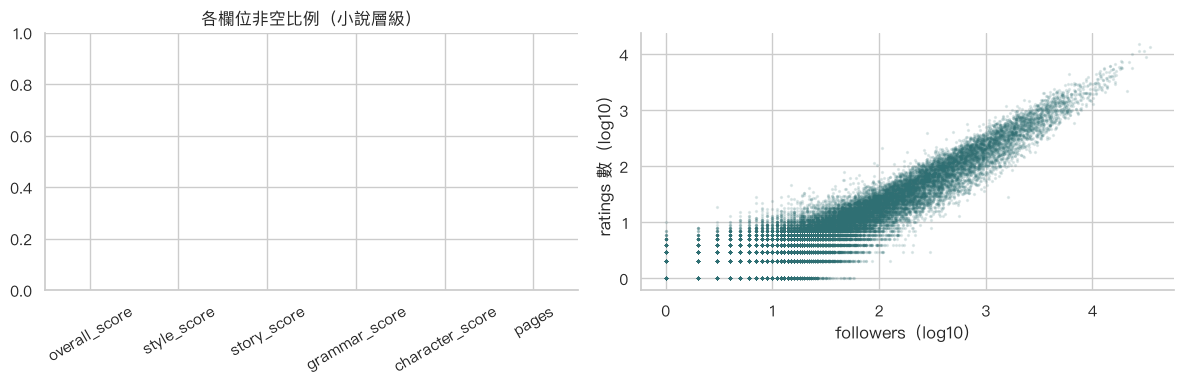

,n,ratings_zero_or_na,med_ratings,med_favorites
fol_bucket,,,,
0,23337,0.920,0.0,0.0
1-9,36222,0.612,0.0,1.0
10-99,18040,0.103,5.0,6.0
100-999,7152,0.036,46.0,68.0
1k-9.9k,2127,0.045,437.0,559.5
10k+,81,0.000,3782.0,5327.0


In [11]:
bins = [-1, 0, 9, 99, 999, 9999, np.inf]; labels = ["0", "1-9", "10-99", "100-999", "1k-9.9k", "10k+"]
fi["fol_bucket"] = pd.cut(fi.followers, bins=bins, labels=labels)
tab = fi.groupby("fol_bucket", observed=True).agg(n=("fiction_id","size"), ratings_zero_or_na=("ratings", lambda s: (s.fillna(0) == 0).mean()),
                                                   med_ratings=("ratings","median"), med_favorites=("favorites","median"))
S["ratings_by_followers"] = tab.round(4).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fi[SC].notna().mean().plot.bar(ax=ax[0], color="#c8553d"); ax[0].set_ylim(0, 1); ax[0].set_title("各欄位非空比例（小說層級）"); ax[0].tick_params(axis="x", rotation=30)
ax[1].scatter(np.log10(1 + fi.followers), np.log10(1 + fi.ratings), s=2, alpha=.12, color="#2f6f73")
ax[1].set_xlabel("followers（log10）"); ax[1].set_ylabel("ratings 數（log10）")
plt.tight_layout(); save("scores")
tab.round(3)

## 9. Tags 與 Warnings

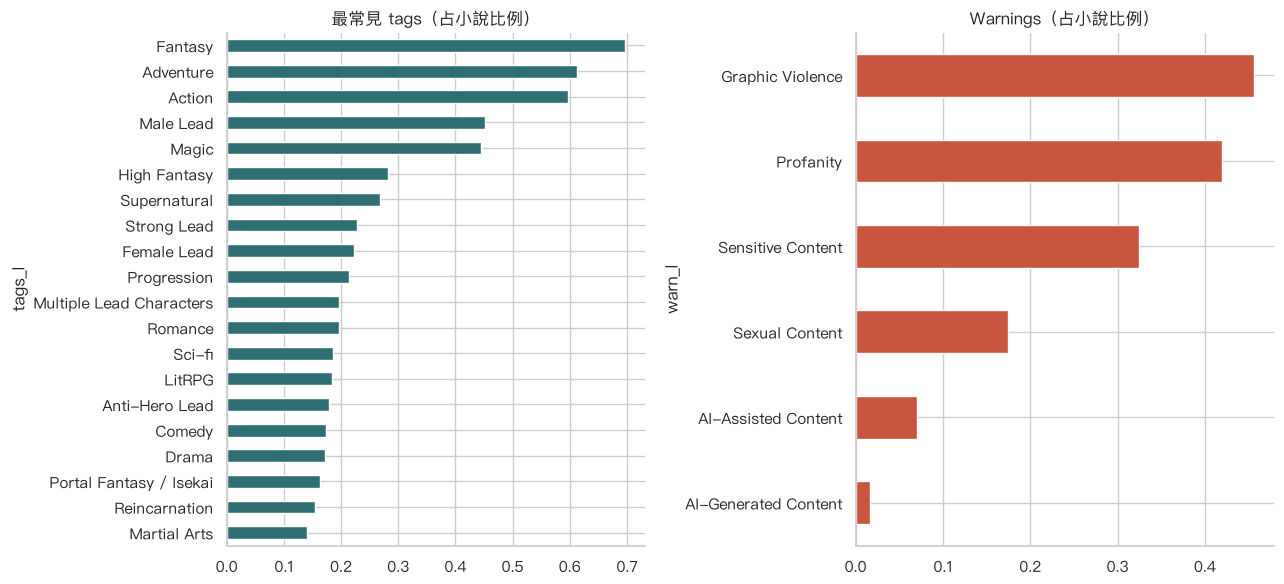

不同 tag 數: 64  無 warning 比例: 0.338


In [12]:
def parse(s):
    try: return json.loads(s) if isinstance(s, str) and s else []
    except Exception: return []
fi["tags_l"] = fi.tags.map(parse); fi["warn_l"] = fi.warnings.map(parse)
S["tags_per_fiction_med"] = float(fi.tags_l.map(len).median())
tag_ct = fi.tags_l.explode().value_counts(); warn_ct = fi.warn_l.explode().value_counts()
S["n_distinct_tags"] = int(len(tag_ct)); S["top_tags"] = (tag_ct.head(25) / len(fi)).round(4).to_dict()
S["warnings"] = (warn_ct / len(fi)).round(4).to_dict(); S["share_no_warning"] = float((fi.warn_l.map(len) == 0).mean())
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
(tag_ct.head(20)[::-1] / len(fi)).plot.barh(ax=ax[0], color="#2f6f73"); ax[0].set_title("最常見 tags（占小說比例）")
(warn_ct[::-1] / len(fi)).plot.barh(ax=ax[1], color="#c8553d"); ax[1].set_title("Warnings（占小說比例）")
plt.tight_layout(); save("tags_warnings")
print("不同 tag 數:", S["n_distinct_tags"], " 無 warning 比例:", round(S["share_no_warning"],3))

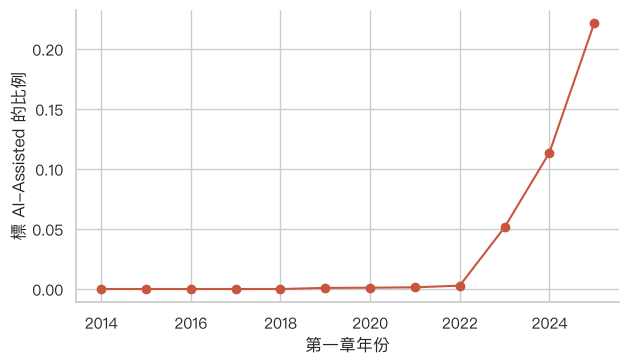

,n,ai
first_year,,
2018,4381,0.000
2019,4429,0.001
2020,6373,0.001
2021,7124,0.001
2022,8526,0.003
2023,11786,0.051
2024,17565,0.114
2025,15820,0.222


In [13]:
fi["ai_assisted"] = fi.warn_l.map(lambda l: "AI-Assisted Content" in l)
ai = fi.groupby("first_year").agg(n=("fiction_id","size"), ai=("ai_assisted","mean"))
S["ai_by_year"] = ai.round(4).to_dict("index")
fig, ax = plt.subplots(figsize=(7, 3.8))
ai[ai.n >= 200].ai.plot(marker="o", ax=ax, color="#c8553d"); ax.set_ylabel("標 AI-Assisted 的比例"); ax.set_xlabel("第一章年份")
save("ai_assisted_by_year")
ai.round(3).tail(8)

## 10. 章節文字長度

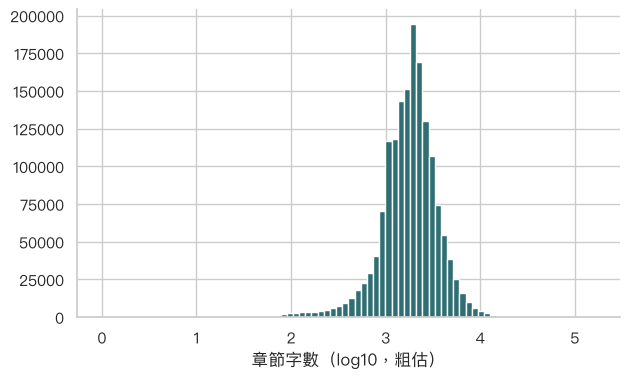

{0.01: 139.0, 0.1: 812.0, 0.5: 1866.0, 0.9: 3838.0, 0.99: 8166.0}  少於 100 字: 0.006


In [14]:
S["words_q"] = ch.words.quantile([.01,.1,.5,.9,.99]).round(0).to_dict()
S["share_short_chapter"] = float((ch.words < 100).mean())
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(np.log10(ch.words.clip(lower=1)), bins=80, color="#2f6f73"); ax.set_xlabel("章節字數（log10，粗估）")
save("chapter_words")
print(S["words_q"], " 少於 100 字:", round(S["share_short_chapter"],4))

## 11. 對 Project 1 的可行性：前 3 章 → 之後會不會熱門

要點：(1) 至少 3 章的小說有多少；(2) 熱度與「連載多久」的關係，這是主要洩漏來源；(3) 「前 3 章」的文字量。

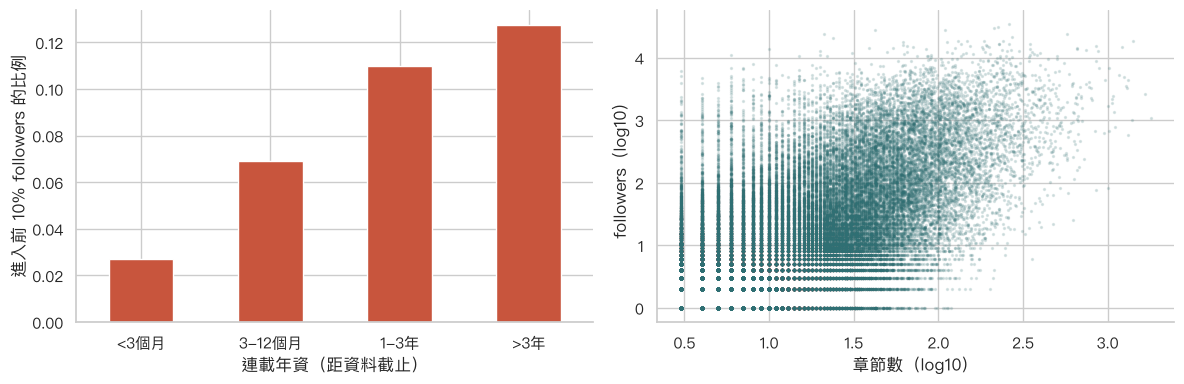

至少 3 章: 57,997 本；前 10% 門檻 followers >= 244；前三章字數中位數 5082
Spearman(年資, followers)= 0.355  Spearman(章數, followers)= 0.559


,n,top10_rate,med_followers
age_bucket,,,
<3個月,6387,0.027,2.0
3-12個月,11325,0.069,3.0
1-3年,16184,0.110,6.0
>3年,24101,0.128,15.0


In [15]:
first3 = (ch.sort_values(["fiction_id","release_datetime"]).groupby("fiction_id").head(3).groupby("fiction_id").words.sum().rename("first3_words"))
fi = fi.join(first3, on="fiction_id")
scrape = ch.release_datetime.max()
fi["age_days"] = (scrape - fi.first_release).dt.days
cand = fi[fi.n_chapters >= 3].copy()
thr = cand.followers.quantile(.9); cand["top10"] = cand.followers >= thr
S["cand_n"] = int(len(cand)); S["top10_threshold"] = float(thr)
S["first3_words_med"] = float(cand.first3_words.median())
S["rho_age_followers"] = float(spearmanr(cand.age_days, cand.followers)[0])
S["rho_nchap_followers"] = float(spearmanr(cand.n_chapters, cand.followers)[0])
cand["age_bucket"] = pd.cut(cand.age_days, [-1, 90, 365, 1095, 1e9], labels=["<3個月","3-12個月","1-3年",">3年"])
age = cand.groupby("age_bucket", observed=True).agg(n=("fiction_id","size"), top10_rate=("top10","mean"), med_followers=("followers","median"))
S["age_table"] = age.round(4).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
age.top10_rate.plot.bar(ax=ax[0], color="#c8553d"); ax[0].set_ylabel("進入前 10% followers 的比例"); ax[0].set_xlabel("連載年資（距資料截止）"); ax[0].tick_params(axis="x", rotation=0)
ax[1].scatter(np.log10(cand.n_chapters), np.log10(1 + cand.followers), s=2, alpha=.15, color="#2f6f73"); ax[1].set_xlabel("章節數（log10）"); ax[1].set_ylabel("followers（log10）")
plt.tight_layout(); save("age_leakage")
print(f"至少 3 章: {len(cand):,} 本；前 10% 門檻 followers >= {thr:.0f}；前三章字數中位數 {S['first3_words_med']:.0f}")
print("Spearman(年資, followers)=", round(S["rho_age_followers"],3), " Spearman(章數, followers)=", round(S["rho_nchap_followers"],3))
age.round(3)

## 12. 重複與品質

In [16]:
S["dup_title_share"] = float(fi.title.duplicated(keep=False).mean())
S["dup_desc_share"] = float(fi.description.duplicated(keep=False).mean())
S["empty_desc_share"] = float((fi.description.fillna("").str.strip().str.len() < 20).mean())
S["no_cover_share"] = float(fi.cover_url.fillna("").str.contains("nocover").mean())
a = fi.groupby("author").size()
S["author_fictions_q"] = a.describe(percentiles=[.5,.9,.99]).round(1).to_dict()
S["top_author_share"] = float(a.sort_values(ascending=False).head(100).sum() / len(fi))
print({k: round(v,4) for k, v in S.items() if k in ["dup_title_share","dup_desc_share","empty_desc_share","no_cover_share","top_author_share"]})
print(S["author_fictions_q"])

{'dup_title_share': 0.0498, 'dup_desc_share': 0.0028, 'empty_desc_share': 0.0013, 'no_cover_share': 0.2653, 'top_author_share': 0.0257}
{'count': 56458.0, 'mean': 1.5, 'std': 1.5, 'min': 1.0, '50%': 1.0, '90%': 3.0, '99%': 7.0, 'max': 62.0}


In [17]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, float) and np.isnan(o): return None
    return o
Path("../reports/eda/summary.json").write_text(json.dumps(clean(S), ensure_ascii=False, indent=1))
print("saved summary.json,", len(list(FIG.glob('*.png'))), "figures")

saved summary.json, 9 figures
